# 부산항 개선안: 신항 터미널 간 선석 대기 쏠림 완화

### 1. 제목

  신항 터미널 간 선석스케줄을 벗어나 도착한 선박으로 인해 병목현상이 발생한다. 이를 완화하기 위해 비어 있는 다른 신항 터미널 선석에 임시 배정해,
  특정 터미널에 몰리는 선석 대기를 줄인다.

### 2. 대상 개선기회

선석스케줄을 벗어난 입항과 출항으로 선석 대기 발생

### 3. 영향받는 주체

- 신항 터미널 운영사(PNIT, PNC, HJNC, HPNT, BNCT, BCT 등): 선석 계획과 야드 운영
- 선사와 얼라이언스(Gemini, Premier Alliance, MSC 등): 기항 일정, 다음 항만 연결
- 부산항만공사: 항만 전체 선석 조정, Port-i·PORT-MIS 운영
- 부산지방해양수산청: 입항 신고와 정박지 관리
- 화주와 운송사: 수출 컨테이너 반입 일정, 환적 연결

### 4. 현재 상태(As-is)

- 20~24년
- 같은 달 터미널별 평균 대기: PNIT 약 80시간, HPNT 52시간, PNC 약 32시간 [검증 필요]
- 7일 평균 선박 대기: 1월 약 1일(2주차 선석 대기 1.5~2일), 6월 1.17일, 8월 1.11일, 9월 1.33일 [검증 필요]
- 8월 10~23일 평균 접안 지연 8.7시간, 대기 17척 [검증 필요]


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = ['Malgun Gothic']
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('선박입출항.csv', encoding='cp949')

df = df[df['입항연도'].between(2020, 2024)].copy()

df.head(3)

,청코드,선박키,입항연도,입항회수,업체코드,업체명,차항지코드1,차항지코드2,차항지명,적재톤수,...,출항예정일시,전출항지출항일시,전출항지코드1,전출항지코드2,전출항지명,입항일시,출항일시,양하톤수,선원수,전체승객수
30229,20,9684067,2020,1,BSZ7250,그린월드(주),TW,KHH,KAOHSIUNG,2622.0,...,2020-01-29 18:00,2020-01-19 20:00,CN,NBO,NINGBO,2020-01-21 09:00,2020-01-29 16:00,0.0,21.0,NaN
30230,20,120330,2020,6,BSK2661,보성기업,KR,YOS,여수,0.0,...,2020-01-16 18:00,2020-01-15 4:30,KR,YOS,여수,2020-01-15 12:20,2020-01-16 18:00,0.0,6.0,0.0
30231,20,A8SI6,2020,1,KMC0660,우성마리타임(주),US,KIN,"KINGSMOUNTAIN, NC",60500.0,...,2020-01-23 6:00,2020-01-20 12:00,CN,YAN,YANGSHAN,2020-01-22 12:00,2020-01-23 09:00,5223.0,21.0,NaN


In [37]:
origin = df.copy()

print("원본 데이터 행 수:", len(origin))

원본 데이터 행 수: 224724


In [38]:
cols = [
    '입항연도',
    '출항예정일시',
    '출항일시',
    '선박종류명'
]

df = origin[cols].copy()

df.head()

,입항연도,출항예정일시,출항일시,선박종류명
30229,2020,2020-01-29 18:00,2020-01-29 16:00,냉동.냉장선
30230,2020,2020-01-16 18:00,2020-01-16 18:00,기타 유조선
30231,2020,2020-01-23 6:00,2020-01-23 09:00,풀컨테이너선
30448,2020,2020-01-18 21:00,2020-01-18 20:14,시멘트운반선
39432,2020,2020-01-16 16:55,2020-01-16 16:55,석유제품 운반선


In [39]:
df['입항연도'] = pd.to_numeric(
    df['입항연도'],
    errors='coerce'
)

df = df[df['입항연도'].between(2020, 2024)].copy()

df = df[df['선박종류명'] == '풀컨테이너선'].copy()

print("분석 대상 행 수:", len(df))

df.head()

분석 대상 행 수: 64112


,입항연도,출항예정일시,출항일시,선박종류명
30231,2020,2020-01-23 6:00,2020-01-23 09:00,풀컨테이너선
39433,2020,2020-01-22 6:00,2020-01-22 15:12,풀컨테이너선
39434,2020,2020-01-20 8:00,2020-01-20 07:40,풀컨테이너선
39435,2020,2020-01-21 0:00,2020-01-20 23:00,풀컨테이너선
39438,2020,2020-01-20 14:00,2020-01-20 20:00,풀컨테이너선


In [40]:
df['출항예정일시'] = pd.to_datetime(
    df['출항예정일시'],
    errors='coerce'
)

df['출항일시'] = pd.to_datetime(
    df['출항일시'],
    errors='coerce'
)

df.dtypes

입항연도               int64
출항예정일시    datetime64[us]
출항일시      datetime64[us]
선박종류명                str
dtype: object

In [41]:
# 출항예정일시가 비어 있는 데이터
print(
    "출항예정일시 결측값:",
    df['출항예정일시'].isna().sum()
)

# 출항일시가 비어 있는 데이터
print(
    "출항일시 결측값:",
    df['출항일시'].isna().sum()
)

출항예정일시 결측값: 6
출항일시 결측값: 0


In [42]:
print("출항예정일시 연도별 건수")

print(
    df['출항예정일시']
    .dt.year
    .value_counts(dropna=False)
    .sort_index()
)

print("\n출항일시 연도별 건수")

all = df['출항일시'].dt.year.value_counts(dropna=False).sort_index()
all = all.drop(2025)
all

출항예정일시 연도별 건수
출항예정일시
2020.0    13331
2021.0    12032
2022.0    12106
2023.0    13653
2024.0    12899
2025.0       53
2026.0        2
2027.0        5
2031.0        1
2032.0        6
2042.0        1
2055.0        1
2201.0        4
2202.0        2
2203.0        2
2204.0        5
2323.0        1
2424.0        2
NaN           6
Name: count, dtype: int64

출항일시 연도별 건수


출항일시
2020    13329
2021    12034
2022    12114
2023    13668
2024    12908
Name: count, dtype: int64

In [43]:
# 정상적인 출항연도 범위 설정
start_date = pd.Timestamp('2020-01-01')
end_date = pd.Timestamp('2026-01-01')

# 정상 날짜 조건
valid_date = (
    (df['출항예정일시'] >= start_date) &
    (df['출항예정일시'] < end_date) &
    (df['출항일시'] >= start_date) &
    (df['출항일시'] < end_date)
)

# 제외되는 데이터 따로 보관
date_errors = df[~valid_date].copy()

# 정상 범위 데이터만 선택
df_clean = df[valid_date].copy()

print('전처리 전 데이터 수:', len(df))
print('제외된 데이터 수:', len(date_errors))
print('전처리 후 데이터 수:', len(df_clean))

전처리 전 데이터 수: 64112
제외된 데이터 수: 38
전처리 후 데이터 수: 64074


In [44]:
df_clean['지연시간'] = (
    df_clean['출항일시'] - df_clean['출항예정일시']
).dt.total_seconds() / 3600

df_clean['지연시간'].describe()

count    64074.000000
mean         0.673473
std        198.361745
min     -26297.100000
25%         -0.116667
50%          0.783333
75%          3.416667
max      10555.083333
Name: 지연시간, dtype: float64

In [45]:
df = df_clean[
    (df_clean['지연시간'] >= 1) &
    (df_clean['지연시간'] < 72)
]
df

all = df_clean.groupby('입항연도').size()

In [46]:
result['전체출항건수'] =result['입항연도'].map(all)

result['지연율(%)'] = (
   result['지연건수'] / result['전체출항건수'] * 100
).round(2)

result

,입항연도,전체출항건수,지연건수,지연율(%)
0,2020,13373,6043,45.19
1,2021,12035,5906,49.07
2,2022,12101,5414,44.74
3,2023,13664,6324,46.28
4,2024,12901,5877,45.55


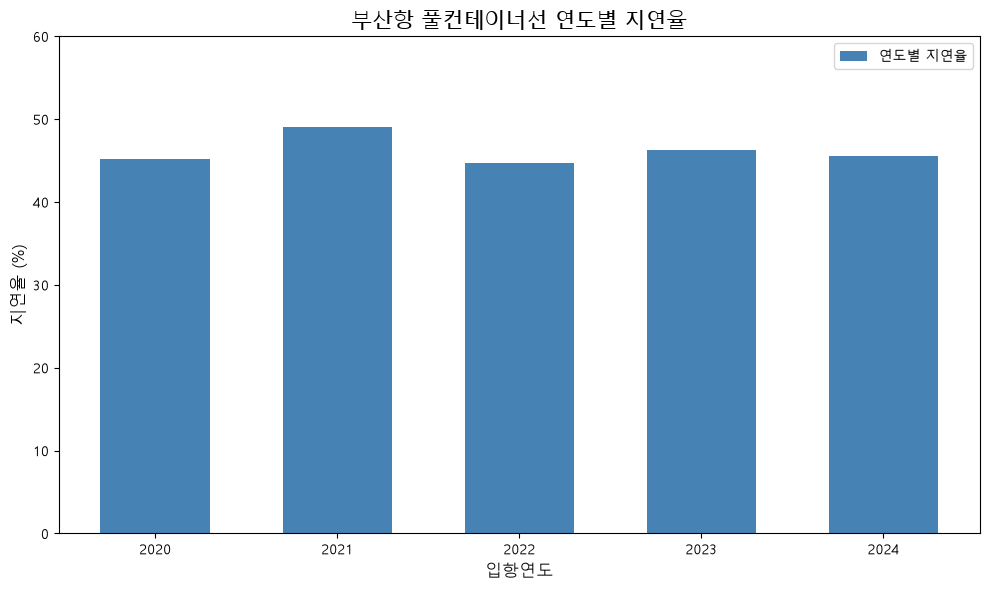

In [48]:
# 그래프 크기
plt.figure(figsize=(10, 6))

# 연도별 막대그래프
bars = plt.bar(
    result['입항연도'].astype(str),
    result['지연율(%)'],
    color='steelblue',
    width=0.6,
    label='연도별 지연율'
)


# 제목 및 축 설정
plt.title('부산항 풀컨테이너선 연도별 지연율', fontsize=15)
plt.xlabel('입항연도', fontsize=12)
plt.ylabel('지연율 (%)', fontsize=12)

plt.ylim(0, 60)
plt.legend()

plt.tight_layout()
plt.show()

### 5. 원인 가설

선사와 터미널은 정해진 요일·시간대(선석 윈도우)로 선석을 계약한다. 선박이 제 시간에 오면 문제가 없지만, 해외 항만 적체나 태풍으로 늦게 도착하면 계약 윈도우를 놓치고 같은 터미널의 다음 빈 윈도우를 기다린다. 선박이 그 사이 다른 터미널 선석이 비어 있어도 쓰지 못한다. 그래서 정시성이 떨어질수록 항만 전체 대기보다 터미널 간 대기 편차가 먼저 커진다.

보조 가설: 대기가 길어진 터미널은 수출 컨테이너가 야드에 오래 머물러 장치율이 오르고(2026년 1월 약 95%), 본선 작업이 더 느려지는 악순환이 생긴다.


### 6. 해결방안과 대안

- (주안) 스케줄 이탈 선박의 터미널 간 임시 선석 배정: 윈도우를 정해진 시간 이상 벗어난 선박을, 부산항만공사가 신항 전체 선석 현황을 보고 여유 터미널에 한 번만 배정한다. 비용 정산 규칙을 미리 정해 둔다.
- (대안 1) ETA 기반 도착 조정(Just-in-Time Arrival): 직전 항만 출항 시점에 부산 접안 가능 시각을 알려 감속 운항하게 한다. 정박지 대기를 바다 위 감속으로 바꿔 연료와 배출도 줄인다.
- (대안 2) 지연 선박 전용 예비 선석 시간대: 각 터미널이 주간 선석 계획에 예비 윈도우를 남겨 두고 지연 선박에 우선 배정한다.
- (대안 3) 터미널 간 선석 현황 공유 대시보드: Port-i에 터미널별 선석 점유와 대기 예상을 실시간 공개해 선사가 스스로 조정하게 한다.


### 7. 목표 상태(To-be)

윈도우를 놓친 선박은 접안 가능한 신항 선석으로 바로 배정되고, 부산항 전체의 선석 대기는 터미널과 관계없이 비슷한 수준으로 유지된다. 정시성이 낮아지는 시기에도 터미널 간 대기 편차가 크게 벌어지지 않는다.


### 8. 근거

- **늦게 도착한 배가 늘었다.** 직전 항구에서 부산까지 걸린 시간이 같은 출발항 중앙값보다 12시간 넘게 긴 배의 비중은 15.9%(2019)에서 31.5%(2021)로 두 배가 됐고, 2024년에도 26.7%다.
- **늦게 온 배가 더 오래 머문다.** 그런 배의 재항시간 중앙값은 2021년 24.7시간으로 제때 온 배(21.4시간)보다 3.3시간 길었다. 2020~2024년 내내 2.1~3.3시간 길었다. 2019년에는 차이가 없었다(16.6시간 대 17.0시간).
- **장기 재항이 늘었다.** 48시간 넘게 머문 컨테이너선은 715척(2019)에서 1,151척(2021)으로 늘었고, 2024년은 888척이다. 늦게 온 배의 48시간 이상 비중은 2021년 10.6%로 제때 온 배(8.6%)보다 높았다.
- **항만이 붐빌 때 더 오래 머문다.** 입항할 때 항만 안 컨테이너선이 43척 이상이면 재항시간 중앙값이 21.0시간, 32척 이하면 18.8시간이다.
- **2021년이 이상치다.** 입항은 2019년보다 14.8% 적었는데 재항시간 중앙값은 17.0시간에서 22.4시간으로 늘었다. 물량이 아니라 도착 흐름과 항만 안 처리가 막힌 해다.
- **이 CSV로 확인할 수 없는 것:** 터미널 사이 대기 편차, 다른 터미널의 빈 선석 여부, 정박지 대기와 하역 시간의 구분. 모두 부두·접안 시각 데이터가 있어야 한다.

| 연도 | 2019 | 2020 | 2021 | 2022 | 2023 | 2024 |
|---|---|---|---|---|---|---|
| 12h+ 늦게 도착한 비중 | 15.9% | 26.3% | 31.5% | 28.2% | 30.5% | 26.7% |
| 재항시간 중앙값: 늦게 온 배 | 16.6h | 20.4h | 24.7h | 23.6h | 20.9h | 22.2h |
| 재항시간 중앙값: 제때 온 배 | 17.0h | 17.8h | 21.4h | 21.0h | 18.8h | 20.0h |
| 48h+ 비중: 늦게 온 배 | 4.1% | 6.7% | 10.6% | 9.4% | 6.4% | 6.8% |
| 48h+ 비중: 제때 온 배 | 5.0% | 6.3% | 8.6% | 8.3% | 6.2% | 6.6% |
| 48h+ 장기 재항 척수 | 715 | 894 | 1,151 | 1,078 | 880 | 888 |

### 9. 기대효과와 측정지표

모두 같은 CSV로 매달 계산할 수 있는 지표만 넣었다. 기준선은 2024년 값이다.

| 구분 | 지표 | 정의 | 2019 | 2021 | 2024(기준) | 목표 |
|---|---|---|---|---|---|---|
| 선행 | 늦게 온 배의 추가 재항시간 | 12h+ 늦게 온 배 − 제때 온 배, 재항시간 중앙값 차이 | −0.4h | 3.3h | 2.2h | 0h (2019년 수준) |
| 선행 | 늦게 온 배의 장기 재항 비중 | 12h+ 늦게 온 배 중 48h 넘게 머문 비중 | 4.1% | 10.6% | 6.8% | 5% 이하 |
| 후행 | 재항시간 중앙값 | 출항일시 − 입항일시 | 17.0h | 22.4h | 20.6h | 19h 이하 |
| 후행 | 48h+ 장기 재항 척수 | 연간 척수 | 715척 | 1,151척 | 888척 | 750척 이하 |
| 참고 | 늦게 도착한 배 비중 | 같은 출발항 중앙값보다 12h+ 늦게 온 비중 | 15.9% | 31.5% | 26.7% | 목표 없음 (부산이 통제할 수 없음) |

**기대효과 (추정):** 늦게 온 배의 추가 재항시간 2.2시간을 없애면, 2024년 늦게 온 배 약 3,500척 기준 연 약 7,700 선석시간이 줄어든다. 재항시간에는 대기와 하역이 섞여 있어서 상한 추정이다.

**효과를 가리는 방법:** 늦게 온 배와 제때 온 배의 차이를 지표로 쓰면, 세계 정시성이나 물동량 변화처럼 두 집단에 함께 오는 영향이 빠진다. 개선안이 듣는다면 이 차이만 줄어야 한다.

**추가 데이터가 필요한 지표:** 터미널 간 대기 편차(최대/최소)와 다른 터미널 임시 배정 비율은 부두·접안 시각 데이터를 받은 뒤에 기준선을 잡는다.

---

**계산 방법 (PyCharm 재현):** `analysis/cause_charts.py`의 `load()`로 데이터를 읽는다. 대상은 컨테이너선, 재항 0시간 초과·240시간 미만, 처리 화물 상위 0.1% 제외, 출항지연 −72~240시간이다. 늦게 도착한 배는 `voy`(입항일시 − 전출항지출항일시, 0~720시간)가 같은 `전출항지코드2`의 `voy` 중앙값보다 12시간 넘게 긴 배다.


### 10. 실행조건

- 부산항만공사, 터미널 운영사, 선사 간 임시 배정 협약과 하역료·이송비 정산 기준
- 타 터미널 접안 시 환적·수출 컨테이너 이송 방안(타부두 환적 비용 증가와 연계 검토)
- PORT-MIS·Port-i의 ETA 수집과 터미널 선석 계획 데이터 연동
- 항만운영 관련 규정과 터미널 임대 계약 조건 검토


### 11. 가정과 위험

- 가정: 대기가 길 때 다른 신항 터미널에 실제로 여유 선석이 있다. 터미널별 선석 점유율 원자료로 확인해야 한다.
- 가정: 늦은 선박이 다른 터미널에 접안해도 하역 생산성이 크게 떨어지지 않는다.
- 위험: 다른 터미널에 내린 컨테이너를 원래 터미널로 옮기면서 타부두 환적 물량과 비용
- 위험: 터미널 운영사마다 계약 선사와 이해관계가 달라 협조가 어렵다.
- 미확인: 정시성 저하 상당 부분은 해외 항만 적체와 기상 때문이라 부산이 통제할 수 없다. 이 개선안은 지연 자체가 아니라 지연이 부산에서 대기로 바뀌는 정도를 줄이는 데 한정된다.
- 미확인: 선석 대기가 화주의 비용과 선박 운항에 주는 영향은 정량화하지 않았다.
- 미확인: 터미널 별 선석 점유와 대기시간 데이터를 못구해 비교하지 않았다.